## Imports and settings

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
FIG_DIR = Path("../reports/figures")
MODEL_DIR = Path("../models")
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## Clean the data

In [16]:
df = pd.read_csv(DATA_PATH)

# The 11 blank TotalCharges belong to tenure-0 customers who haven't been billed yet -> 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# customerID is an identifier with no predictive value
df = df.drop(columns=["customerID"])

# Target: Yes/No -> 1/0
df["Churn"] = (df["Churn"] == "Yes").astype(int)

X = df.drop(columns=["Churn"])
y = df["Churn"]

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
print(X.shape, "| numeric:", len(num_cols), "| categorical:", len(cat_cols))

(7043, 19) | numeric: 3 | categorical: 16


In [17]:
# Stratified so both sets keep the 26.5% churn ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "churn rate", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "churn rate", round(y_test.mean(), 3))

Train: (5634, 19) churn rate 0.265
Test:  (1409, 19) churn rate 0.265


In [18]:
# Scale numeric features (needed for KNN distances and LR coefficients)
# One-hot encode categoricals; binary Yes/No columns become a single 0/1 column
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])
print("Features after encoding:", preprocessor.fit(X_train).transform(X_train).shape[1])

Features after encoding: 40


In [19]:
def evaluate(name, setting, model, X_te, y_te):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    return {"Model": name, "Setting": setting,
            "Accuracy": accuracy_score(y_te, y_pred),
            "Precision": precision_score(y_te, y_pred),
            "Recall": recall_score(y_te, y_pred),
            "F1": f1_score(y_te, y_pred),
            "ROC-AUC": roc_auc_score(y_te, y_prob)}

models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
}

In [20]:
results = []
baseline_models = {}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    baseline_models[name] = pipe
    results.append(evaluate(name, "Baseline", pipe, X_test, y_test))

pd.DataFrame(results).round(3)

,Model,Setting,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,Baseline,0.762,0.554,0.532,0.543,0.777
1,Logistic Regression,Baseline,0.806,0.657,0.559,0.604,0.842
2,Random Forest,Baseline,0.781,0.612,0.481,0.539,0.821


In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "KNN": {"clf__n_neighbors": [5, 11, 21, 31, 51],
            "clf__weights": ["uniform", "distance"],
            "clf__p": [1, 2]},                       # 1 = Manhattan, 2 = Euclidean
    "Logistic Regression": {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    "Random Forest": {"clf__n_estimators": [200, 400],
                      "clf__max_depth": [5, 10, None],
                      "clf__min_samples_leaf": [1, 5, 10],
                      "clf__max_features": ["sqrt", 0.5]},
}

tuned_models = {}
for name, clf in models.items():
    # SMOTE sits INSIDE the pipeline, so it only oversamples the training folds,
    # never the validation fold or the test set (prevents data leakage)
    pipe = ImbPipeline([("prep", preprocessor),
                        ("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("clf", clf)])
    gs = GridSearchCV(pipe, param_grids[name], scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned_models[name] = gs.best_estimator_
    print(f"{name}: best params {gs.best_params_}, CV F1 = {gs.best_score_:.3f}")
    results.append(evaluate(name, "Tuned + SMOTE", gs.best_estimator_, X_test, y_test))

KNN: best params {'clf__n_neighbors': 31, 'clf__p': 1, 'clf__weights': 'uniform'}, CV F1 = 0.614
Logistic Regression: best params {'clf__C': 0.1}, CV F1 = 0.633
Random Forest: best params {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 10, 'clf__n_estimators': 200}, CV F1 = 0.636


In [22]:
results_df = pd.DataFrame(results).set_index(["Model", "Setting"]).round(3)
results_df.to_csv("../reports/model_results.csv")
results_df

,,Accuracy,Precision,Recall,F1,ROC-AUC
Model,Setting,,,,,
KNN,Baseline,0.762,0.554,0.532,0.543,0.777
Logistic Regression,Baseline,0.806,0.657,0.559,0.604,0.842
Random Forest,Baseline,0.781,0.612,0.481,0.539,0.821
KNN,Tuned + SMOTE,0.710,0.472,0.799,0.594,0.822
Logistic Regression,Tuned + SMOTE,0.737,0.503,0.786,0.614,0.839
Random Forest,Tuned + SMOTE,0.761,0.537,0.722,0.616,0.838


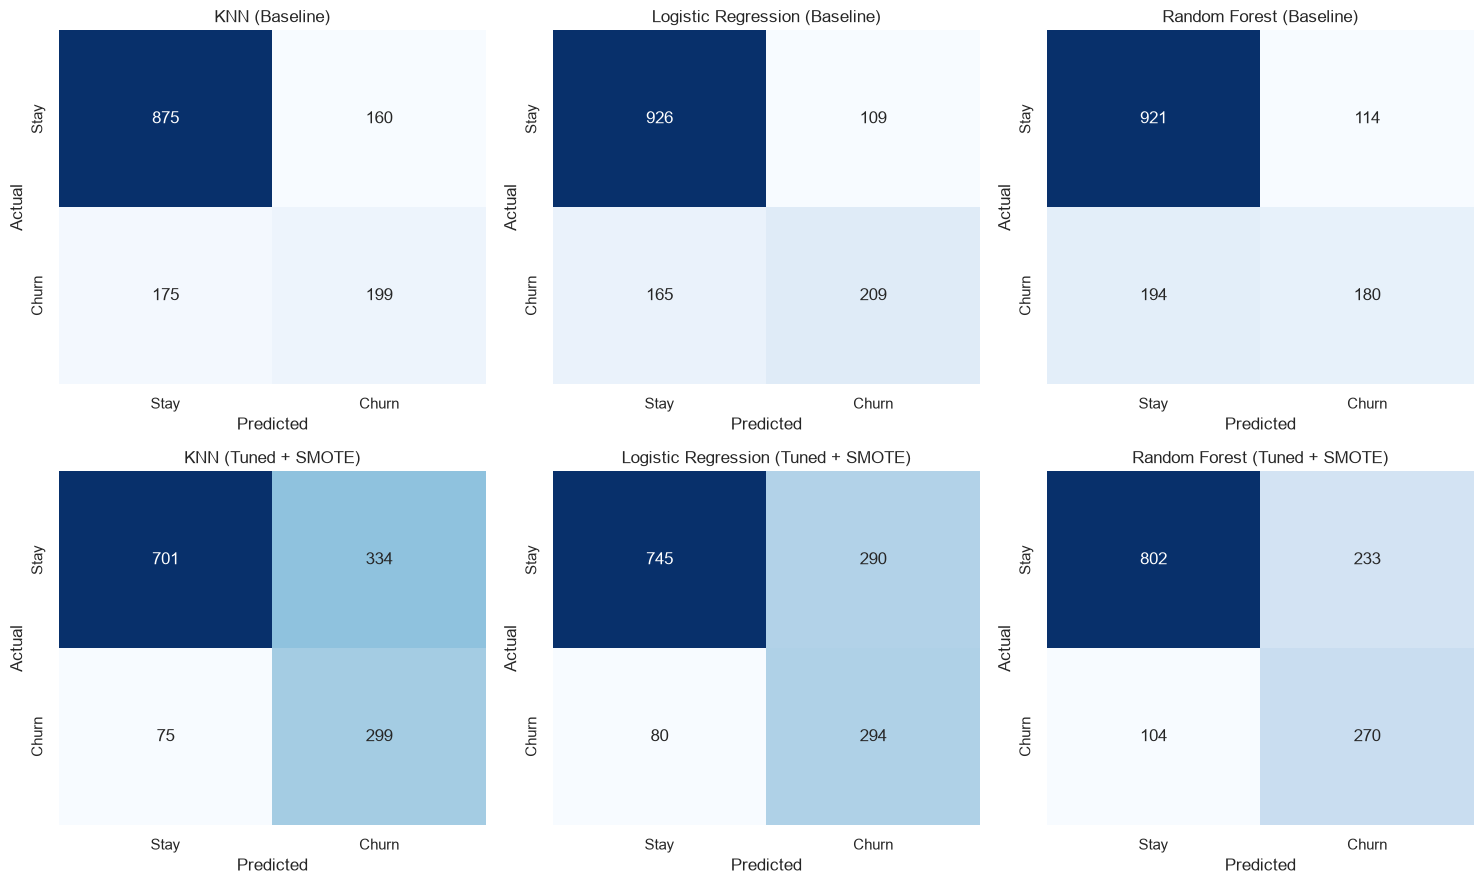

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (setting, mdict) in enumerate([("Baseline", baseline_models),
                                        ("Tuned + SMOTE", tuned_models)]):
    for col, (name, m) in enumerate(mdict.items()):
        cm = confusion_matrix(y_test, m.predict(X_test))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[row, col],
                    xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
        axes[row, col].set_title(f"{name} ({setting})")
        axes[row, col].set_xlabel("Predicted")
        axes[row, col].set_ylabel("Actual")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_confusion_matrices.png", dpi=150)
plt.show()

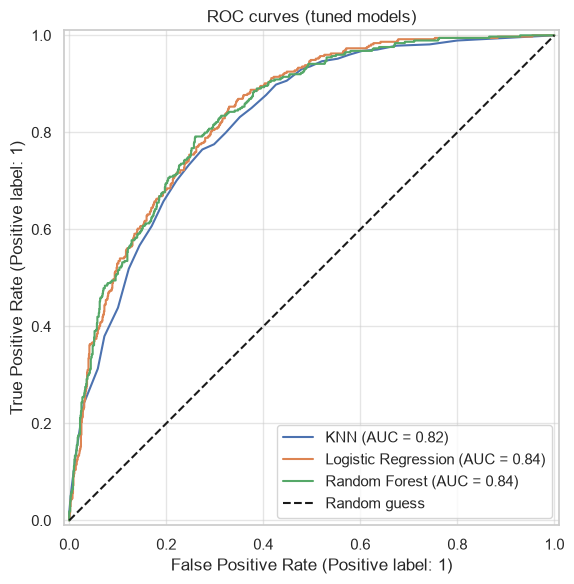

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in tuned_models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves (tuned models)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "07_roc_curves.png", dpi=150)
plt.show()

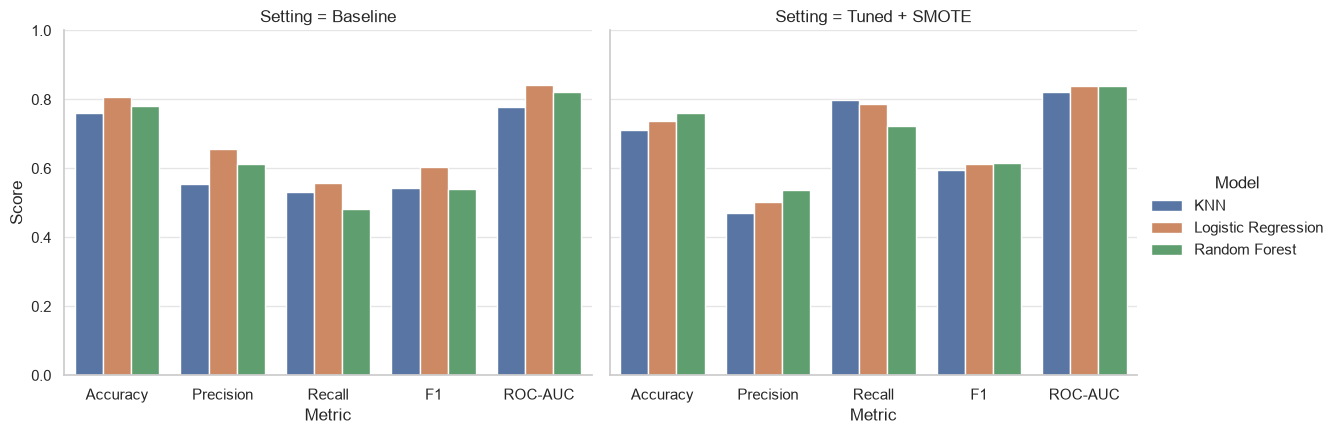

In [25]:
plot_df = results_df.reset_index().melt(id_vars=["Model", "Setting"],
                                        var_name="Metric", value_name="Score")
g = sns.catplot(data=plot_df, x="Metric", y="Score", hue="Model", col="Setting",
                kind="bar", height=4.5, aspect=1.3)
g.set(ylim=(0, 1))
plt.savefig(FIG_DIR / "08_metric_comparison.png", dpi=150)
plt.show()

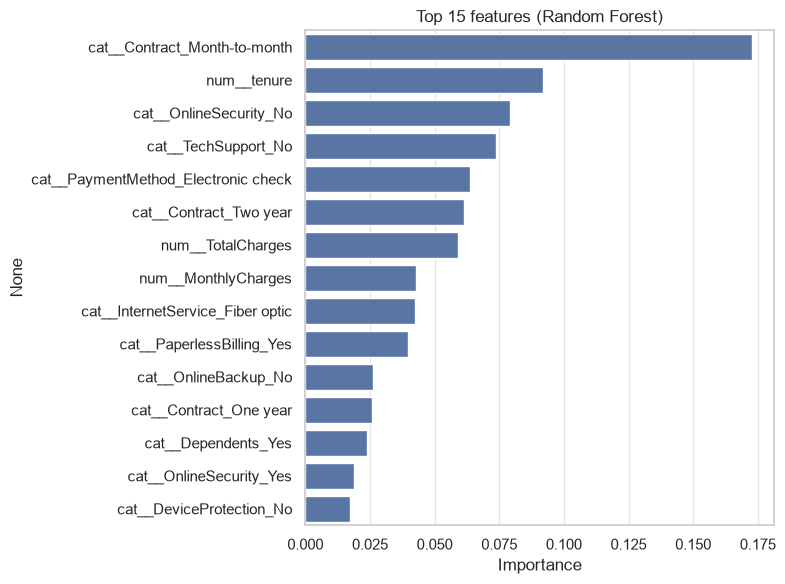

num__tenure                           -1.142
cat__Contract_Two year                -0.645
cat__Dependents_Yes                   -0.357
cat__InternetService_DSL              -0.319
cat__MultipleLines_No                 -0.209
cat__OnlineSecurity_Yes               -0.190
cat__TechSupport_Yes                  -0.179
cat__TechSupport_No                    0.242
cat__OnlineSecurity_No                 0.253
cat__PaymentMethod_Electronic check    0.317
cat__InternetService_Fiber optic       0.382
cat__PaperlessBilling_Yes              0.428
num__TotalCharges                      0.515
cat__Contract_Month-to-month           0.702
dtype: float64

In [26]:
rf = tuned_models["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
imp = (pd.Series(rf.named_steps["clf"].feature_importances_, index=feat_names)
       .sort_values(ascending=False).head(15))

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color="#4C72B0", ax=ax)
ax.set_title("Top 15 features (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_rf_feature_importance.png", dpi=150)
plt.show()

# Logistic Regression: positive = raises churn risk, negative = lowers it
lr = tuned_models["Logistic Regression"]
coefs = pd.Series(lr.named_steps["clf"].coef_[0],
                  index=lr.named_steps["prep"].get_feature_names_out()).sort_values()
pd.concat([coefs.head(7), coefs.tail(7)]).round(3)

In [27]:
print(classification_report(y_test, tuned_models["Random Forest"].predict(X_test),
                            target_names=["Stay", "Churn"]))

for name, m in tuned_models.items():
    joblib.dump(m, MODEL_DIR / f"{name.lower().replace(' ', '_')}.joblib")

              precision    recall  f1-score   support

        Stay       0.89      0.77      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

